In [1]:
# Importing all neccessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

In [2]:
# Q1A

# Getting first question dataset
q1_dataset = pd.read_csv('datasets/Q1_Titanic_Passenger_Dataset.csv')
columns = []
datatypes = []

# Getting the columns and their data types
for i in range(0, len(q1_dataset.columns)):
    columns.append(q1_dataset.columns[i])
    datatypes.append(q1_dataset.iloc[0:11, i].dtypes)

# printing the dataset and its information
print(f'{q1_dataset.iloc[0:10]}\n')
print(f'Total rows: {len(q1_dataset)}\n')
print(f'Total columns: {len(q1_dataset.columns)}\n')
print(f'Columns: {columns}\n')
print(f'Column data types: {datatypes}\n')
print(f'numerical columns: {q1_dataset.select_dtypes(include=np.number).columns.tolist()}\n')
print(f'categorical columns: {q1_dataset.select_dtypes(include=object).columns.tolist()}\n')



   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   
5            6         0       3   
6            7         0       1   
7            8         0       3   
8            9         1       3   
9           10         1       2   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   
5                                   Moran, Mr. James    male   NaN      0   
6                            McCarthy, Mr. Timothy J    male  54

In [3]:
# Q1B

# Checking for missing values in the dataset
missing_values = q1_dataset.isnull().sum()

# Printing the missing values and their percentage in the dataset
for column, i in missing_values.items():
    if i > 0:
        print(f'Column {column} has {i} missing values\n'
              f'Percentage of missing values in column {column} is {round((i / len(q1_dataset)) * 100, 2)}%\n')

# removing rows with missing values in the embarked and age columns
print(f'Rows in the dataset before cleaning: {len(q1_dataset)}')
q1_dataset = q1_dataset.dropna(subset=[q1_dataset.columns[11]])
print(f'After removing rows with missing embarked values, the dataset has {len(q1_dataset)} rows\n')
q1_dataset = q1_dataset.dropna(subset=[q1_dataset.columns[5]])
print(f'After removing rows with missing age values, the dataset has {len(q1_dataset)} rows\n')
q1_dataset = q1_dataset.drop(columns=[q1_dataset.columns[10]])
print('removing the Cabin column as it has lots missing values')

# removing duplicate rows based on the first column
q1_dataset = q1_dataset[~q1_dataset.iloc[:, 0].duplicated(keep='first')]
print(f'After removing duplicate rows, the dataset has {len(q1_dataset)} rows\n')
print('All rows have the correct data type')

# grabing age and fare columns for further analysis
age = q1_dataset.iloc[:, 5]
fare = q1_dataset.iloc[:, 9]
age_in_order = []
fare_in_order = []

# Sorting age and fare columns in ascending order
age_in_order = age.sort_values().tolist()
fare_in_order = fare.sort_values().tolist()

# Calculating the first and third quartiles (25th and 75th percentiles) for age and fare
age_q1 = age_in_order[int(len(age_in_order) * .25)]
age_q3 = age_in_order[int(len(age_in_order) * .75)]
fare_q1 = fare_in_order[int(len(fare_in_order) * .25)]
fare_q3 = fare_in_order[int(len(fare_in_order) * .75)]
print(f'25th percentile of age: {age_q1}')
print(f'75th percentile of age: {age_q3}')
print(f'25th percentile of fare: {fare_q1}')
print(f'75th percentile of fare: {fare_q3}')

# Calculating the interquartile range (IQR) for age and fare
age_iqr = age_q3 - age_q1
fare_iqr = fare_q3 - fare_q1

# Calculating the lower and upper bounds for age and fare based on the IQR and 1.5*IQR rule
lower_age_bound = age_q1 - 1.5 * age_iqr
upper_age_bound = age_q3 + 1.5 * age_iqr
lower_fare_bound = fare_q1 - 1.5 * fare_iqr
upper_fare_bound = fare_q3 + 1.5 * fare_iqr
print(f'Lower age bound: {lower_age_bound}')
print(f'Upper age bound: {upper_age_bound}')
print(f'Lower fare bound: {lower_fare_bound}')
print(f'Upper fare bound: {upper_fare_bound}')

# Removing outliers based on the calculated bounds for age and fare
q1_dataset = q1_dataset[
    (q1_dataset.iloc[:, 5] >= lower_age_bound) & (q1_dataset.iloc[:, 5] <= upper_age_bound) &
    (q1_dataset.iloc[:, 9] >= lower_fare_bound) & (q1_dataset.iloc[:, 9] <= upper_fare_bound)
]

print(f'After removing outliers, the dataset has {len(q1_dataset)} rows')
print('I removed rows with missing values because they could affect the accuracy of the analysis, especially when calculating statistics like the mean and performing hypothesis tests.')
print('I have first removed rows with missing values and then removed outliers based on age and fare by calculating the IQR and applying the 1.5*IQR rule.')


Column Age has 177 missing values
Percentage of missing values in column Age is 19.87%

Column Cabin has 687 missing values
Percentage of missing values in column Cabin is 77.1%

Column Embarked has 2 missing values
Percentage of missing values in column Embarked is 0.22%

Rows in the dataset before cleaning: 891
After removing rows with missing embarked values, the dataset has 889 rows

After removing rows with missing age values, the dataset has 712 rows

removing the Cabin column as it has lots missing values
After removing duplicate rows, the dataset has 712 rows

All rows have the correct data type
25th percentile of age: 20.0
75th percentile of age: 38.0
25th percentile of fare: 8.05
75th percentile of fare: 33.0
Lower age bound: -7.0
Upper age bound: 65.0
Lower fare bound: -29.374999999999996
Upper fare bound: 70.425
After removing outliers, the dataset has 610 rows
I removed rows with missing values because they could affect the accuracy of the analysis, especially when calcula

In [4]:
# Q1C

# Calculating descriptive statistics for age and fare columns
age_mean = q1_dataset.iloc[:, 5].mean()
age_median = q1_dataset.iloc[:, 5].median()
age_std = q1_dataset.iloc[:, 5].std()
age_mode = q1_dataset.iloc[:, 5].mode()[0]
age_range = q1_dataset.iloc[:, 5].max() - q1_dataset.iloc[:, 5].min()
age_variance = q1_dataset.iloc[:, 5].var()
age_sd = q1_dataset.iloc[:, 5].std()
age_freq = q1_dataset.iloc[:, 5].value_counts()
age_skewness = q1_dataset.iloc[:, 5].skew()
age_kurtosis = q1_dataset.iloc[:, 5].kurt()

fare_mean = q1_dataset.iloc[:, 9].mean()
fare_median = q1_dataset.iloc[:, 9].median()
fare_std = q1_dataset.iloc[:, 9].std()
fare_variance = q1_dataset.iloc[:, 9].var()
fare_sd = q1_dataset.iloc[:, 9].std()
fare_mode = q1_dataset.iloc[:, 9].mode()[0]
fare_freq = q1_dataset.iloc[:, 9].value_counts()
fare_skewness = q1_dataset.iloc[:, 9].skew()
fare_kurtosis = q1_dataset.iloc[:, 9].kurt()

print(f'Mean of age: {age_mean}')
print(f'Median of age: {age_median}')
print(f'Mode of age: {age_mode}')
print(f'Range of age: {age_range}')
print(f'Mean of fare: {fare_mean}')
print(f'Median of fare: {fare_median}')
print(f'Mode of fare: {fare_mode}')
print(f'Standard deviation of fare: {fare_std}')
print(f'Variance of fare: {fare_variance}')
print(f'Standard deviation (SD) of fare: {fare_sd}')
print(f'Frequency of age values: {age_freq}')
print(f'Frequency of fare values: {fare_freq}')
print(f'Skewness of age: {age_skewness}')
print(f'Kurtosis of age: {age_kurtosis}')
print(f'Skewness of fare: {fare_skewness}')
print(f'Kurtosis of fare: {fare_kurtosis}')

# Calculating the survival rates for males, females, and the total population
total_survival_rate = q1_dataset.iloc[:, 1].mean()
male_survival_rate = q1_dataset[q1_dataset.iloc[:, 4] == 'male'].iloc[:, 1].mean()
female_survival_rate = q1_dataset[q1_dataset.iloc[:, 4] == 'female'].iloc[:, 1].mean()
print(f'Male survival rate: {male_survival_rate}')
print(f'Female survival rate: {female_survival_rate}')
print(f'Total survival rate: {total_survival_rate}')

# Calculating the survival rates for different passenger classes
class1_survival_rate = q1_dataset[q1_dataset.iloc[:, 2] == 1].iloc[:, 1].mean()
class2_survival_rate = q1_dataset[q1_dataset.iloc[:, 2] == 2].iloc[:, 1].mean()
class3_survival_rate = q1_dataset[q1_dataset.iloc[:, 2] == 3].iloc[:, 1].mean()
print(f'Class 1 survival rate: {class1_survival_rate}')
print(f'Class 2 survival rate: {class2_survival_rate}')
print(f'Class 3 survival rate: {class3_survival_rate}')

print('observation 1: Class 1 passengers have the highest survival rate, followed by Class 2 and Class 3.')
print('observation 2: Male passengers have a lower survival rate compared to female passengers.')
print(f'observation 3: The average age of passengers is: {age_mean}')


Mean of age: 28.427459016393442
Median of age: 28.0
Mode of age: 22.0
Range of age: 64.58
Mean of fare: 18.998121147540985
Median of fare: 13.0
Mode of fare: 13.0
Standard deviation of fare: 14.266885681879952
Variance of fare: 203.54402705983117
Standard deviation (SD) of fare: 14.266885681879952
Frequency of age values: Age
22.00    25
24.00    25
28.00    24
19.00    23
30.00    22
         ..
64.00     1
24.50     1
0.67      1
0.42      1
34.50     1
Name: count, Length: 81, dtype: int64
Frequency of fare values: Fare
13.0000    41
26.0000    30
8.0500     29
7.8958     23
10.5000    22
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 178, dtype: int64
Skewness of age: 0.24112036766601763
Kurtosis of age: -0.0285536567209137
Skewness of fare: 1.4192214830687417
Kurtosis of fare: 1.4662212797908558
Male survival rate: 0.19164619164619165
Female survival rate: 0.6945812807881774
Total survival rate: 0.3590163934426229
Class 1 s

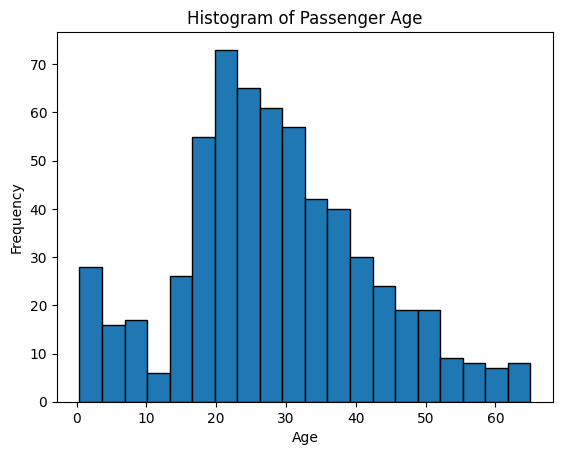

This shows the distribution of passenger ages.This indicates that the majority of passengers are within a 20 to 40 age range.


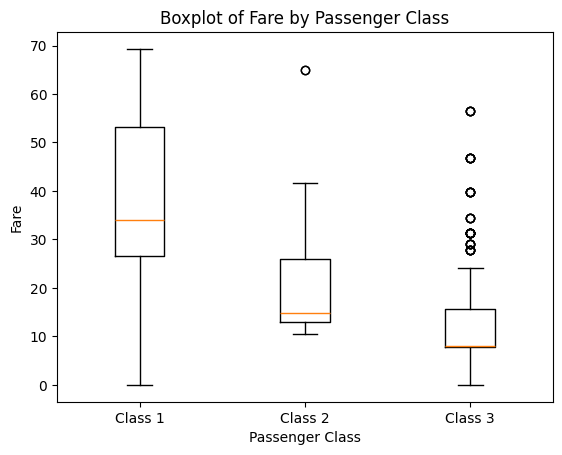

This shows the distribution of fares by passenger class.It shows that most fares are concentrated in the lower range.


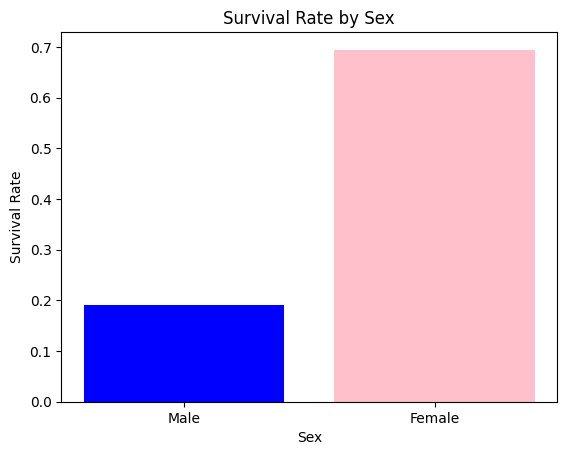

This shows the survival rate by sex.It shows that female passengers have a higher survival rate compared to male passengers.


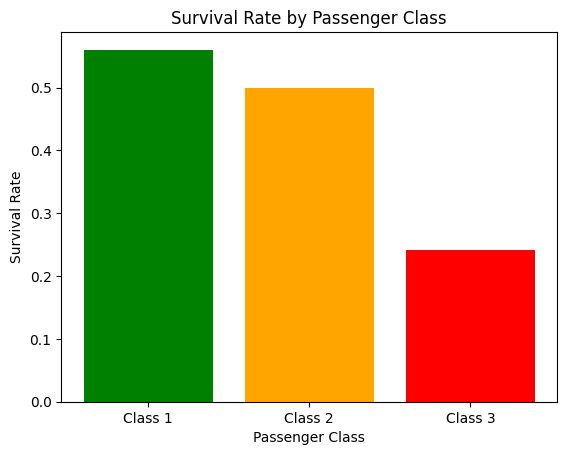

This shows the survival rate by passenger class.It shows that Class 1 passengers have the highest survival rate, followed by Class 2 and Class 3.


In [5]:
# Q1D

#histogram of passanger age
plt.hist(q1_dataset.iloc[:, 5].dropna(), bins=20, edgecolor='black')
plt.title('Histogram of Passenger Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()
print('This shows the distribution of passenger ages.'
      'This indicates that the majority of passengers are within a 20 to 40 age range.')

# boxplot of fare by passenger class
plt.boxplot([q1_dataset[q1_dataset.iloc[:, 2] == 1].iloc[:, 9].dropna(),
             q1_dataset[q1_dataset.iloc[:, 2] == 2].iloc[:, 9].dropna(),
             q1_dataset[q1_dataset.iloc[:, 2] == 3].iloc[:, 9].dropna()],
            tick_labels=['Class 1', 'Class 2', 'Class 3'])
plt.title('Boxplot of Fare by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.show()
print('This shows the distribution of fares by passenger class.'
      'It shows that most fares are concentrated in the lower range.')

# bar chart showing survival rate by sex
sex_survival_rates = [male_survival_rate, female_survival_rate]
sex_labels = ['Male', 'Female']
plt.bar(sex_labels, sex_survival_rates, color=['blue', 'pink'])
plt.title('Survival Rate by Sex')
plt.xlabel('Sex')
plt.ylabel('Survival Rate')
plt.show()
print('This shows the survival rate by sex.'
      'It shows that female passengers have a higher survival rate compared to male passengers.')

# bar chart showing survival rate by passenger class
class_survival_rates = [class1_survival_rate, class2_survival_rate, class3_survival_rate]
class_labels = ['Class 1', 'Class 2', 'Class 3']
plt.bar(class_labels, class_survival_rates, color=['green', 'orange', 'red'])
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()
print('This shows the survival rate by passenger class.'
      'It shows that Class 1 passengers have the highest survival rate, followed by Class 2 and Class 3.')


In [6]:
# Q1E

print('H0: The mean fare is the same for passengers who survived and passengers who did not survive.')
print('H1: The mean fare is different between passengers who survived and passengers who did not survive.')

# t-test
alpha = 0.05
mean_fare_survived = q1_dataset[q1_dataset.iloc[:, 1] == 1].iloc[:, 9].mean()
mean_fare_not_survived = q1_dataset[q1_dataset.iloc[:, 1] == 0].iloc[:, 9].mean()

t_stat, p_value = ttest_ind(q1_dataset[q1_dataset.iloc[:, 1] == 1].iloc[:, 9].dropna(), q1_dataset[q1_dataset.iloc[:, 1] == 0].iloc[:, 9].dropna())
print('t-statistic:', t_stat)
print('p-value:', p_value)
if p_value < alpha:
    print('Reject H0: There is a significant difference in mean fare between passengers who survived and passengers who did not survive.')
else:
    print('Fail to reject H0: There is no significant difference in mean fare between passengers who survived and passengers who did not survive.')


H0: The mean fare is the same for passengers who survived and passengers who did not survive.
H1: The mean fare is different between passengers who survived and passengers who did not survive.
t-statistic: 6.04936407295136
p-value: 2.5417157950158754e-09
Reject H0: There is a significant difference in mean fare between passengers who survived and passengers who did not survive.
